# DENV lineage connectivity across South Asia
Input: lineage_assigned.csv from the previous notebook. Output: tables and figures in /kaggle/working/out.

In [1]:
import os, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import pdist, squareform

P = "/kaggle/working/lineage_assigned.csv"
if not os.path.exists(P):
    c = glob.glob("/kaggle/input/**/lineage_assigned.csv", recursive=True)
    assert c, "Add lineage_assigned.csv as a Kaggle dataset"
    P = c[0]
os.makedirs("out", exist_ok=True)
m = pd.read_csv(P)
m = m[m.lineage.notna() & (m.lineage != "unassigned")].copy()
m["year"] = m.year.astype(int)
m["major"] = m.lineage.str.split(".").str[0]
SERO = {1: "DENV-1", 2: "DENV-2", 3: "DENV-3", 4: "DENV-4"}
print(len(m), "assigned sequences;", m.lineage.nunique(), "lineages;", m.country.nunique(), "countries")


2459 assigned sequences; 60 lineages; 7 countries


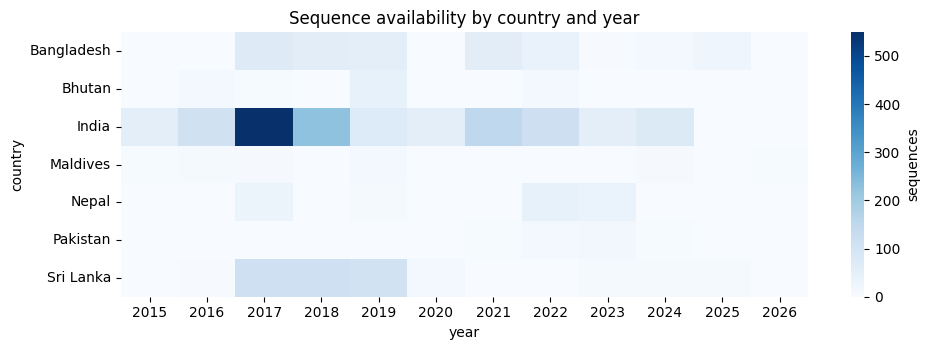

In [2]:
# Table 1: sampling depth by country and year (sampling-bias context)
t1 = pd.crosstab(m.country, m.year)
t1.to_csv("out/table1_sampling_by_year.csv")
plt.figure(figsize=(10, 3.6))
sns.heatmap(t1, cmap="Blues", cbar_kws={"label": "sequences"})
plt.title("Sequence availability by country and year")
plt.tight_layout(); plt.savefig("out/fig1_sampling.png", dpi=200); plt.show()


In [3]:
# Table 2: lineage counts per country and serotype
t2 = pd.crosstab([m.serotype, m.lineage], m.country)
t2.to_csv("out/table2_lineage_by_country.csv")

# Lineage sharing: lineages seen in at least 2 countries versus single-country lineages
rows = []
for (s, l), g in m.groupby(["serotype", "lineage"]):
    cs = sorted(g.country.unique())
    rows.append({"serotype": SERO[s], "lineage": l, "n": len(g), "n_countries": len(cs), "countries": ", ".join(cs),
                 "first_year": g.year.min(), "last_year": g.year.max()})
lin = pd.DataFrame(rows).sort_values(["serotype", "n"], ascending=[True, False])
lin.to_csv("out/table3_lineage_summary.csv", index=False)
print(lin[lin.n >= 20].to_string(index=False))


serotype     lineage   n  n_countries                                               countries  first_year  last_year
  DENV-1      1III_A 223            5            Bangladesh, India, Maldives, Nepal, Pakistan        2015       2026
  DENV-1    1III_A.3  85            3                                    Bhutan, India, Nepal        2015       2024
  DENV-1      1I_H.1  41            3                                 India, Nepal, Sri Lanka        2015       2022
  DENV-1    1III_A.4  40            2                                        India, Sri Lanka        2017       2020
  DENV-1        1I_H  31            1                                                   India        2017       2017
  DENV-1         1IV  25            1                                                   India        2017       2017
  DENV-1    1III_A.1  20            1                                                Pakistan        2022       2024
  DENV-2   2II_F.1.1 475            6 Bangladesh, India, Maldive

In [4]:
cnt = m.groupby(["serotype", "lineage", "country"]).size().rename("n").reset_index()
ncty = cnt[cnt.n >= 3].groupby(["serotype", "lineage"]).country.nunique().rename("nc").reset_index()
x = m.merge(ncty, on=["serotype", "lineage"], how="left")
x["nc"] = x.nc.fillna(1)
x["shared"] = x.nc >= 2
t4 = x.groupby("country").agg(n=("acc", "size"), shared_pct=("shared", lambda s: round(100 * s.mean(), 1)))
t4.to_csv("out/table4_shared_share.csv")
print(t4)

               n  shared_pct
country                     
Bangladesh   325        18.8
Bhutan        78        87.2
India       1462        55.6
Maldives      50        90.0
Nepal        119        94.1
Pakistan      44        50.0
Sri Lanka    381        85.0


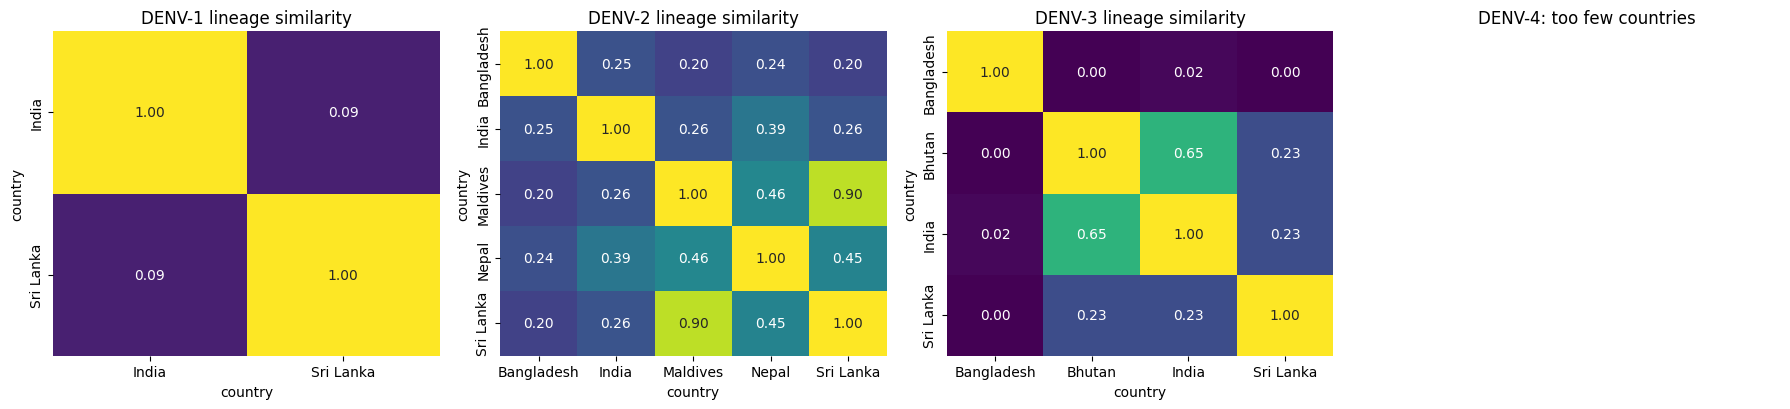

In [5]:
# Figure 2: country similarity per serotype (Bray-Curtis on lineage frequencies), countries with 30+ sequences only
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (s, name) in zip(axes, SERO.items()):
    d = m[m.serotype == s]
    ct = pd.crosstab(d.country, d.lineage)
    ct = ct[ct.sum(axis=1) >= 30]
    if len(ct) < 2:
        ax.set_title(name + ": too few countries"); ax.axis("off"); continue
    fr = ct.div(ct.sum(axis=1), axis=0)
    dist = pd.DataFrame(squareform(pdist(fr.values, "braycurtis")), index=fr.index, columns=fr.index)
    sns.heatmap(1 - dist, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(name + " lineage similarity")
plt.tight_layout(); plt.savefig("out/fig2_country_similarity.png", dpi=200); plt.show()


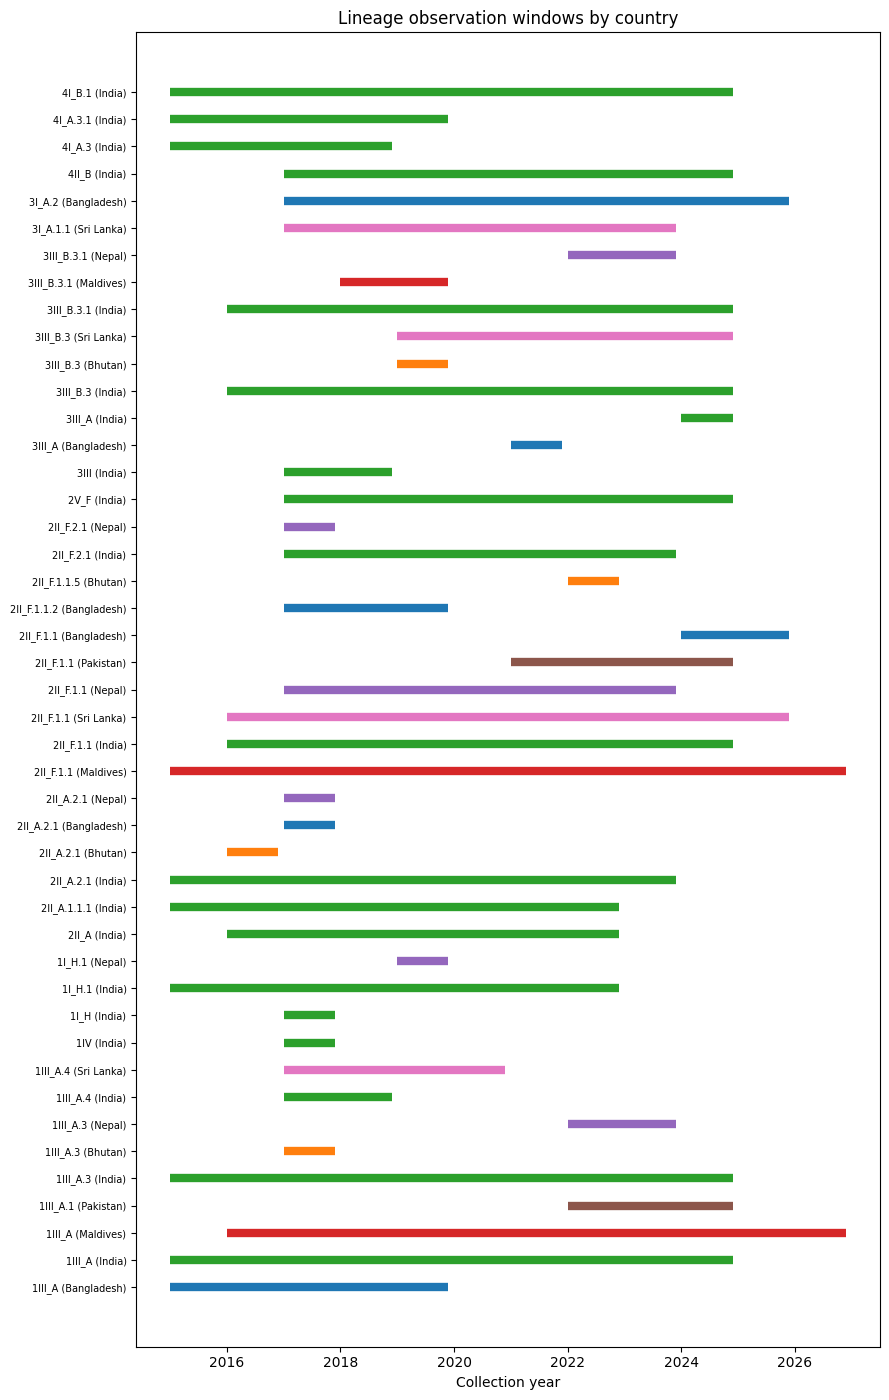

In [6]:
# Figure 3: lineage timelines (first to last year per country) for lineages with 20+ sequences
big = lin[lin.n >= 20].lineage.tolist()
tl = m[m.lineage.isin(big)].groupby(["lineage", "country"]).agg(first=("year", "min"), last=("year", "max"), n=("acc", "size")).reset_index()
tl = tl[tl.n >= 5].sort_values(["lineage", "first"])
fig, ax = plt.subplots(figsize=(9, 0.28 * len(tl) + 1.5))
cols = dict(zip(sorted(tl.country.unique()), sns.color_palette("tab10", tl.country.nunique())))
for i, r in enumerate(tl.itertuples()):
    ax.plot([r.first, r.last + 0.9], [i, i], lw=6, color=cols[r.country], solid_capstyle="butt")
ax.set_yticks(range(len(tl))); ax.set_yticklabels([f"{r.lineage} ({r.country})" for r in tl.itertuples()], fontsize=7)
ax.set_xlabel("Collection year"); ax.set_title("Lineage observation windows by country")
plt.tight_layout(); plt.savefig("out/fig3_timelines.png", dpi=200); plt.show()
